# 01 - Outage data quality

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/config.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt

from src import config as C
from src.data import (load_outages, load_customer_counts, load_census, load_coverage_history,
                      load_dqi)

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

## Annual coverage

In [2]:
# Keep annual summaries; release the full-year frames after each iteration.
summary, per_county, monthly, nulls, schemas = [], [], [], [], {}

for y in C.YEARS:
    df = load_outages([y])
    out = df["customers_out"]
    t = df["run_start_time"]
    slots = (pd.Timestamp(y + 1, 1, 1) - pd.Timestamp(y, 1, 1)) / pd.Timedelta("15min")
    schemas[y] = tuple(df.dtypes.astype(str).items())         # (column, dtype) pairs, compared in section 2

    # Year-level counts
    summary.append({
        "year": y,
        "rows": len(df),
        "counties": df["fips_code"].nunique(),
        "first": t.min(),
        "last": t.max(),
        "minutes_seen": sorted(t.dt.minute.unique()),
        "odd_minute": (t.dt.minute % 15 != 0).sum(),
        "off_grid": (t.ne(t.dt.floor("15min")) & t.notna()).sum(),  # includes seconds
        "dec30_rows": ((t.dt.month == 12) & (t.dt.day == 30)).sum(),
        "dec31_rows": ((t.dt.month == 12) & (t.dt.day == 31)).sum(),
        "null_customers_out": out.isna().sum(),
        "null_time": t.isna().sum(),
        "null_fips": df["fips_code"].isna().sum(),
        "zeros": (out == 0).sum(),
        "negative": (out < 0).sum(),
        "non_integer": (out.dropna() % 1 != 0).sum(),
        "dup_county_time": df.duplicated(["fips_code", "run_start_time"]).sum(),
        "max_out": out.max(),
    })

    # Per county: how many readings, how many null, biggest outage
    c = df.groupby(["fips_code", "county", "state"], dropna=False).agg(
        readings=("customers_out", "size"),
        nulls=("customers_out", lambda s: s.isna().sum()),
        max_out=("customers_out", "max"),
    ).reset_index()
    c["year"] = y
    c["pct_of_possible"] = 100 * c["readings"] / slots
    per_county.append(c)

    # Per month: rows and counties reporting
    m = df.groupby(t.dt.month).agg(rows=("fips_code", "size"), counties=("fips_code", "nunique"))
    m["year"] = y
    monthly.append(m.reset_index(names="month"))

    # Null customers_out by state and month
    n = df[out.isna()]
    nulls.append(n.groupby([n["state"], n["run_start_time"].dt.month.rename("month")]).size()
                  .rename("null_rows").reset_index().assign(year=y))

    del df, out, t, n

summary = pd.DataFrame(summary)
per_county = pd.concat(per_county, ignore_index=True)
monthly = pd.concat(monthly, ignore_index=True)
nulls = pd.concat(nulls, ignore_index=True)
summary

,year,rows,counties,first,last,minutes_seen,odd_minute,off_grid,dec30_rows,dec31_rows,null_customers_out,null_time,null_fips,zeros,negative,non_integer,dup_county_time,max_out
0,2014,358659,410,2014-11-01 04:00:00,2014-12-31 00:00:00,"[0, 15, 30, 45]",0,0,5496,60,0,0,0,0,0,0,0,23816.0
1,2015,2580145,449,2015-01-01 00:00:00,2015-12-31 00:00:00,"[0, 15, 30, 45]",0,0,7121,102,0,0,0,0,0,0,0,92954.0
2,2016,2960707,449,2016-01-01 00:00:00,2016-12-31 00:00:00,"[0, 15, 30, 45]",0,0,8279,65,0,0,0,0,0,0,0,467041.0
3,2017,3388524,508,2017-01-01 00:00:00,2017-12-31 00:00:00,"[0, 15, 30, 45]",0,300,7720,87,28781,0,0,0,0,0,0,1777800.0
4,2018,4553450,508,2018-01-01 00:00:00,2018-12-31 00:00:00,"[0, 15, 30, 45]",0,3611,9305,91,315048,0,0,0,0,0,0,135215.0
5,2019,4808385,525,2019-01-01 00:00:00,2019-12-31 00:00:00,"[0, 15, 30, 35, 45]",23,23,20452,237,275065,0,0,0,0,0,0,137536.0
6,2020,5194354,523,2020-01-01 00:00:00,2020-12-31 00:00:00,"[0, 15, 16, 30, 31, 45, 46]",754,754,11058,117,429447,0,0,0,0,0,0,178832.0
7,2021,4832707,523,2021-01-01 00:00:00,2021-12-31 00:00:00,"[0, 15, 16, 30, 45]",61,61,14742,162,218042,0,0,0,0,0,0,83500.0
8,2022,5289340,527,2022-01-01 00:00:00,2022-12-31 23:45:00,"[0, 15, 30, 45]",0,0,12254,15199,0,0,0,342871,0,0,0,456573.0
9,2023,5412736,527,2023-01-01 00:00:00,2023-12-31 23:45:00,"[0, 15, 30, 31, 45]",165,165,9833,9632,0,0,0,195956,0,0,0,138851.0


## Schema and example readings

In [3]:
print("same columns and dtypes in every year:", len(set(schemas.values())) == 1, "\n")

df = load_outages([2024])
print(df.dtypes, "\n")
print(df.head(), "\n")
print(df["customers_out"].describe().round(1))

same columns and dtypes in every year: True 

fips_code                    str
county                       str
state                        str
customers_out            float32
run_start_time    datetime64[us]
dtype: object 

  fips_code   county    state  customers_out      run_start_time
0     01001  Autauga  Alabama            2.0 2024-01-01 00:15:00
1     01001  Autauga  Alabama            2.0 2024-01-01 00:30:00
2     01001  Autauga  Alabama            2.0 2024-01-01 00:45:00
3     01001  Autauga  Alabama            4.0 2024-01-02 03:15:00
4     01001  Autauga  Alabama            4.0 2024-01-02 03:30:00 

count    5837620.0
mean         479.1
std         6549.7
min            0.0
25%            2.0
50%            4.0
75%           26.0
max       520308.0
Name: customers_out, dtype: float64


In [4]:
bins = [0, 1, 10, 100, 1_000, 10_000, 100_000, 10_000_000]
print(pd.cut(df["customers_out"], bins, right=False).value_counts().sort_index())

customers_out
[0, 1)                 214507
[1, 10)               3471635
[10, 100)             1386077
[100, 1000)            549112
[1000, 10000)          167724
[10000, 100000)         44736
[100000, 10000000)       3829
Name: count, dtype: int64


## Reporting presence

A missing record can mean zero outages or a collection gap. The denominator below is the full calendar year, including the unobserved part of 2014; a stored row may still contain a null outage count.

In [5]:
per_county.groupby("year")["pct_of_possible"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2014,410.0,2.5,3.2,0.0,0.5,1.3,2.9,16.2
2015,449.0,16.4,20.0,0.0,3.1,9.0,21.0,98.2
2016,449.0,18.8,21.1,0.0,3.9,10.8,25.7,98.4
2017,508.0,19.0,19.8,0.0,5.0,12.7,24.6,92.4
2018,508.0,25.6,21.6,0.0,9.8,19.6,34.4,99.1
2019,525.0,26.1,20.7,0.0,12.1,20.8,33.7,99.5
2020,523.0,28.3,21.4,0.4,12.7,22.7,37.4,99.6
2021,523.0,26.4,21.4,0.1,11.6,20.4,34.1,99.5
2022,527.0,28.6,21.7,0.0,12.9,24.2,39.7,99.7


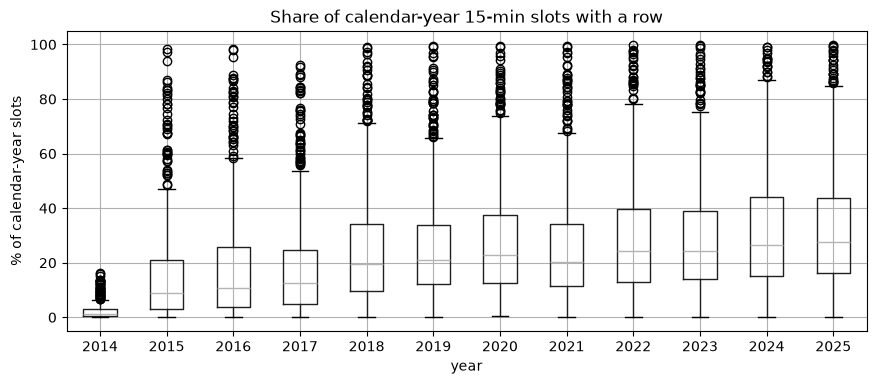

In [6]:
per_county.boxplot(column="pct_of_possible", by="year", figsize=(10, 4))
plt.title("Share of calendar-year 15-min slots with a row")
plt.suptitle("")
plt.ylabel("% of calendar-year slots")
plt.show()

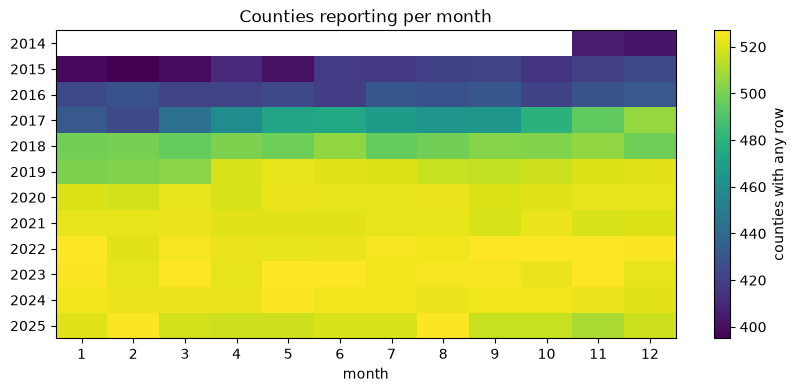

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,405.0,403.0
2015,398.0,395.0,399.0,411.0,401.0,418.0,417.0,421.0,422.0,415.0,420.0,424.0
2016,424.0,428.0,422.0,422.0,424.0,419.0,431.0,428.0,431.0,421.0,429.0,432.0
2017,432.0,424.0,445.0,459.0,472.0,474.0,468.0,464.0,465.0,480.0,495.0,506.0
2018,499.0,500.0,496.0,501.0,498.0,505.0,496.0,499.0,503.0,502.0,505.0,498.0
2019,501.0,502.0,504.0,519.0,522.0,521.0,520.0,516.0,515.0,517.0,520.0,521.0
2020,520.0,518.0,522.0,519.0,523.0,522.0,522.0,523.0,520.0,521.0,522.0,522.0
2021,522.0,522.0,523.0,521.0,521.0,521.0,522.0,522.0,519.0,523.0,519.0,520.0
2022,527.0,521.0,525.0,523.0,522.0,523.0,525.0,524.0,527.0,527.0,527.0,526.0


In [7]:
grid = monthly.pivot(index="year", columns="month", values="counties").reindex(columns=range(1, 13))
plt.figure(figsize=(10, 4))
plt.imshow(grid, aspect="auto", cmap="viridis")
plt.colorbar(label="counties with any row")
plt.xticks(range(12), range(1, 13))
plt.yticks(range(len(grid)), grid.index)
plt.xlabel("month")
plt.title("Counties reporting per month")
plt.show()
grid

The 2014-2021 files stop at December 31 00:00, leaving almost all of that day unobserved.

In [8]:
summary[["year", "last", "dec30_rows", "dec31_rows"]]

,year,last,dec30_rows,dec31_rows
0,2014,2014-12-31 00:00:00,5496,60
1,2015,2015-12-31 00:00:00,7121,102
2,2016,2016-12-31 00:00:00,8279,65
3,2017,2017-12-31 00:00:00,7720,87
4,2018,2018-12-31 00:00:00,9305,91
5,2019,2019-12-31 00:00:00,20452,237
6,2020,2020-12-31 00:00:00,11058,117
7,2021,2021-12-31 00:00:00,14742,162
8,2022,2022-12-31 23:45:00,12254,15199
9,2023,2023-12-31 23:45:00,9833,9632


In [9]:
summary.loc[summary["off_grid"] > 0, ["year", "minutes_seen", "odd_minute", "off_grid"]]

,year,minutes_seen,odd_minute,off_grid
3,2017,"[0, 15, 30, 45]",0,300
4,2018,"[0, 15, 30, 45]",0,3611
5,2019,"[0, 15, 30, 35, 45]",23,23
6,2020,"[0, 15, 16, 30, 31, 45, 46]",754,754
7,2021,"[0, 15, 16, 30, 45]",61,61
9,2023,"[0, 15, 30, 31, 45]",165,165


## Null outage counts

In [10]:
summary[["year", "rows", "null_customers_out"]].assign(
    pct_null=lambda d: (100 * d["null_customers_out"] / d["rows"]).round(2))

,year,rows,null_customers_out,pct_null
0,2014,358659,0,0.00
1,2015,2580145,0,0.00
2,2016,2960707,0,0.00
3,2017,3388524,28781,0.85
4,2018,4553450,315048,6.92
5,2019,4808385,275065,5.72
6,2020,5194354,429447,8.27
7,2021,4832707,218042,4.51
8,2022,5289340,0,0.00
9,2023,5412736,0,0.00


In [11]:
nulls.pivot_table(index="year", columns="state", values="null_rows", aggfunc="sum", fill_value=0)

state,Alabama,Florida,Georgia,North Carolina,South Carolina,Tennessee
year,,,,,,
2017,586,18940,5369,703,999,2184
2018,73339,85646,78501,15565,19884,42113
2019,14078,30568,138868,42740,17548,31263
2020,38463,73842,115059,109410,31138,61535
2021,54611,44796,49244,23323,5575,40493
2025,7251,36811,100814,45722,207890,90946


In [12]:
nulls.pivot_table(index="year", columns="month", values="null_rows", aggfunc="sum", fill_value=0)

month,1,2,3,4,5,6,7,8,9,10,11,12
year,,,,,,,,,,,,
2017,0,0,0,0,0,0,0,0,0,0,5483,23298
2018,46980,95343,17549,6269,9304,13502,13345,11889,23922,21190,29609,26146
2019,27600,24806,13558,88135,6642,11396,28892,14625,8947,10773,8781,30910
2020,99410,17218,65175,46243,55276,35859,15609,12566,20609,10441,26827,24214
2021,11300,37961,21855,30884,25254,7999,13686,9167,6724,15894,23260,14058
2025,42470,17273,67891,51296,73792,43165,49306,24267,13428,26801,29466,50279


In [13]:
has_null = per_county[per_county["nulls"] > 0].copy()
has_null["pct_null"] = 100 * has_null["nulls"] / has_null["readings"]
has_null.groupby("year")["pct_null"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
year,,,,,,,,
2017,500.0,3.3,12.7,0.0,0.1,0.3,0.7,100.0
2018,500.0,11.2,18.2,0.0,0.9,3.5,13.8,100.0
2019,520.0,10.6,14.0,0.0,1.8,5.1,14.5,100.0
2020,521.0,13.4,16.6,0.1,2.9,7.7,17.1,100.0
2021,521.0,9.0,14.6,0.0,1.3,3.2,9.9,100.0
2025,527.0,12.6,21.1,0.0,1.0,3.4,12.6,100.0


## County coverage

In [14]:
census = load_census()
study = census.drop_duplicates("fips_code")[["fips_code", "county_name"]]
seen = set(per_county["fips_code"])
print(f"{len(seen)} of {len(study)} study-area counties appear in EAGLE-I at least once")
study[~study["fips_code"].isin(seen)]

529 of 534 study-area counties appear in EAGLE-I at least once


,fips_code,county_name
468,47085,"Humphreys County, Tennessee"
469,47039,"Decatur County, Tennessee"
479,47071,"Hardin County, Tennessee"
504,47005,"Benton County, Tennessee"
519,47135,"Perry County, Tennessee"


In [15]:
print("FIPS codes not in the census list:", sorted(seen - set(study["fips_code"])))
names = per_county.groupby("fips_code")[["county", "state"]].nunique()
names[(names > 1).any(axis=1)]

FIPS codes not in the census list: []


,county,state
fips_code,,


In [16]:
per_county.pivot_table(index="year", columns="state", values="fips_code", aggfunc="nunique")

state,Alabama,Florida,Georgia,North Carolina,South Carolina,Tennessee
year,,,,,,
2014,22,65,155,86,46,36
2015,30,67,157,99,46,50
2016,29,67,157,99,46,51
2017,65,67,158,100,46,72
2018,65,67,157,100,46,73
2019,66,67,159,100,46,87
2020,65,67,159,100,46,86
2021,65,67,159,100,46,86
2022,66,67,159,100,46,89


## Customer-count estimates

In [17]:
mcc = load_customer_counts()
mcc = mcc[mcc["fips_code"].isin(study["fips_code"])]
print(f"MCC has {len(mcc)} of {len(study)} study counties")
study[~study["fips_code"].isin(mcc["fips_code"])]

MCC has 528 of 534 study counties


,fips_code,county_name
319,37075,"Graham County, North Carolina"
332,37099,"Jackson County, North Carolina"
335,37173,"Swain County, North Carolina"
341,37113,"Macon County, North Carolina"
343,37175,"Transylvania County, North Carolina"
371,37087,"Haywood County, North Carolina"


A peak above the modeled customer total flags a discrepancy in the outage count, denominator, or both.

In [18]:
peaks = per_county.merge(mcc[["fips_code", "Customers"]], on="fips_code", how="left")
peaks["peak_share"] = peaks["max_out"] / peaks["Customers"].where(peaks["Customers"] > 0)
print(peaks["peak_share"].describe().round(3))
peaks[peaks["peak_share"] > 1].sort_values("peak_share", ascending=False)[
    ["year", "fips_code", "county", "state", "max_out", "Customers", "peak_share"]].head(20)

count    5912.000
mean        2.169
std        74.534
min         0.000
25%         0.075
50%         0.180
75%         0.397
max      5477.500
Name: peak_share, dtype: float64


,year,fips_code,county,state,max_out,Customers,peak_share
5285,2024,37089,Henderson,North Carolina,131460.0,24.0,5477.500000
2660,2019,37089,Henderson,North Carolina,21165.0,24.0,881.875000
3184,2020,37089,Henderson,North Carolina,19644.0,24.0,818.500000
2149,2018,37089,Henderson,North Carolina,15685.0,24.0,653.541667
4231,2022,37089,Henderson,North Carolina,11430.0,24.0,476.250000
5812,2025,37089,Henderson,North Carolina,10372.0,24.0,432.166667
1156,2016,37089,Henderson,North Carolina,9604.0,24.0,400.166667
4758,2023,37089,Henderson,North Carolina,9024.0,24.0,376.000000
1642,2017,37089,Henderson,North Carolina,8533.0,24.0,355.541667
708,2015,37089,Henderson,North Carolina,6473.0,24.0,269.708333


In [19]:
print("county-years with peak > all customers, by state:")
peaks[peaks["peak_share"] > 1]["state"].value_counts()

county-years with peak > all customers, by state:


state
North Carolina    248
Georgia            78
Florida            46
South Carolina     21
Tennessee          16
Alabama            14
Name: count, dtype: int64

MCC-to-housing ratios are a plausibility check, not an identity: housing units and utility customers measure different things.

In [20]:
housing = census[census["acs_year"] == 2023][["fips_code", "county_name", "housing_units"]]
check = housing.merge(mcc[["fips_code", "Customers"]], on="fips_code", how="left")
check["customers_per_home"] = check["Customers"] / check["housing_units"]
check["state"] = check["fips_code"].str[:2].map(C.STATES)
print(check.groupby("state")["customers_per_home"].agg(
    median="median", below_half=lambda s: (s < 0.5).sum(), counties="size").round(2))
check.sort_values("customers_per_home").head(15)

       median  below_half  counties
state                              
AL       1.09           0        67
FL       1.21           0        67
GA       1.23           0       159
NC       0.50          48       100
SC       1.22           0        46
TN       1.16           0        95


,fips_code,county_name,housing_units,Customers,customers_per_home,state
337,37089,"Henderson County, North Carolina",57338,24.0,0.000419,NC
293,37001,"Alamance County, North Carolina",75456,925.0,0.012259,NC
357,37129,"New Hanover County, North Carolina",117236,2544.0,0.021700,NC
324,37063,"Durham County, North Carolina",149150,6008.0,0.040282,NC
383,37181,"Vance County, North Carolina",19423,863.0,0.044432,NC
352,37119,"Mecklenburg County, North Carolina",491721,28172.0,0.057293,NC
384,37183,"Wake County, North Carolina",481999,46622.0,0.096726,NC
311,37037,"Chatham County, North Carolina",35013,3797.0,0.108445,NC
310,37035,"Catawba County, North Carolina",72028,8165.0,0.113359,NC
355,37125,"Moore County, North Carolina",49419,5708.0,0.115502,NC


## State coverage and regional quality

State coverage fractions describe customers tracked, not the completeness of individual county-hours.

In [21]:
cov = load_coverage_history()
cov = cov[cov["state"].isin(C.STATES.values())].copy()
cov["year"] = pd.to_datetime(cov["year"], format="%m/%d/%y").dt.year
cov.pivot(index="year", columns="state", values="max_pct_covered")

state,AL,FL,GA,NC,SC,TN
year,,,,,,
2018,0.79,0.97,0.90,0.82,0.99,0.55
2019,0.81,0.97,0.86,0.90,0.99,0.73
2020,0.81,0.97,0.88,0.91,0.99,0.73
2021,0.81,0.98,0.90,0.92,0.99,0.73
2022,0.81,0.98,0.91,0.92,0.99,0.75


DQI is a regional quality index. All six study states are in FEMA Region 4; it cannot resolve individual missing readings.

In [22]:
dqi = load_dqi()
dqi[dqi["fema"] == 4]

,fema,year,success_rate,percent_enabled,spatial_precision,cust_coverage,max_covered,total_customers,DQI
15,4,2018,98.861757,98.118301,78.191252,85.274387,27610605,32378544,74.674709
16,4,2019,98.794257,86.897518,71.365230,89.215870,29304643,32846895,65.047792
17,4,2020,98.700305,99.562188,76.823177,90.135368,30044515,33332659,77.485160
18,4,2021,99.456306,99.063035,76.919332,90.771997,30614057,33726323,85.155162
19,4,2022,98.928670,98.153542,76.742177,91.236277,31073335,34058092,79.172999
